##STROKE PREDICTION MODEL

First, we include require libraries like numpy, pandas, etc

In [57]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

Open the csv file

In [58]:
df = pd.read_csv('healthcare-dataset-stroke-data.csv')

#Understanding the Dataset

In [59]:
df.shape


(5110, 12)

In [60]:
df.head()

,id,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,9046,Male,67.0,0,1,Yes,Private,Urban,228.69,36.6,formerly smoked,1
1,51676,Female,61.0,0,0,Yes,Self-employed,Rural,202.21,NaN,never smoked,1
2,31112,Male,80.0,0,1,Yes,Private,Rural,105.92,32.5,never smoked,1
3,60182,Female,49.0,0,0,Yes,Private,Urban,171.23,34.4,smokes,1
4,1665,Female,79.0,1,0,Yes,Self-employed,Rural,174.12,24.0,never smoked,1


In [61]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5110 entries, 0 to 5109
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   id                 5110 non-null   int64  
 1   gender             5110 non-null   object 
 2   age                5110 non-null   float64
 3   hypertension       5110 non-null   int64  
 4   heart_disease      5110 non-null   int64  
 5   ever_married       5110 non-null   object 
 6   work_type          5110 non-null   object 
 7   Residence_type     5110 non-null   object 
 8   avg_glucose_level  5110 non-null   float64
 9   bmi                4909 non-null   float64
 10  smoking_status     5110 non-null   object 
 11  stroke             5110 non-null   int64  
dtypes: float64(3), int64(4), object(5)
memory usage: 479.2+ KB


In [62]:
df.describe()

,id,age,hypertension,heart_disease,avg_glucose_level,bmi,stroke
count,5110.000000,5110.000000,5110.000000,5110.000000,5110.000000,4909.000000,5110.000000
mean,36517.829354,43.226614,0.097456,0.054012,106.147677,28.893237,0.048728
std,21161.721625,22.612647,0.296607,0.226063,45.283560,7.854067,0.215320
min,67.000000,0.080000,0.000000,0.000000,55.120000,10.300000,0.000000
25%,17741.250000,25.000000,0.000000,0.000000,77.245000,23.500000,0.000000
50%,36932.000000,45.000000,0.000000,0.000000,91.885000,28.100000,0.000000
75%,54682.000000,61.000000,0.000000,0.000000,114.090000,33.100000,0.000000
max,72940.000000,82.000000,1.000000,1.000000,271.740000,97.600000,1.000000


In [63]:
df.describe(include='object')

,gender,ever_married,work_type,Residence_type,smoking_status
count,5110,5110,5110,5110,5110
unique,3,2,5,2,4
top,Female,Yes,Private,Urban,never smoked
freq,2994,3353,2925,2596,1892


In [64]:
df["stroke"].value_counts()

stroke
0    4861
1     249
Name: count, dtype: int64

In [65]:
df.isnull().sum()

id                     0
gender                 0
age                    0
hypertension           0
heart_disease          0
ever_married           0
work_type              0
Residence_type         0
avg_glucose_level      0
bmi                  201
smoking_status         0
stroke                 0
dtype: int64

In [66]:
df.columns

Index(['id', 'gender', 'age', 'hypertension', 'heart_disease', 'ever_married',
       'work_type', 'Residence_type', 'avg_glucose_level', 'bmi',
       'smoking_status', 'stroke'],
      dtype='object')

Creating seperate list of columns which are numeric(Because ML is done on the numeric data)

In [67]:
num_cols = df.select_dtypes(include=np.number).columns.tolist()

In [68]:
num_cols 

['id',
 'age',
 'hypertension',
 'heart_disease',
 'avg_glucose_level',
 'bmi',
 'stroke']

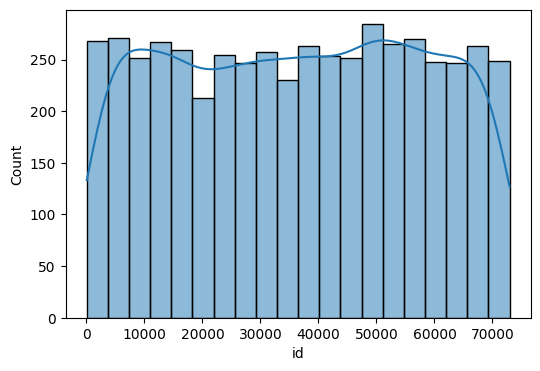

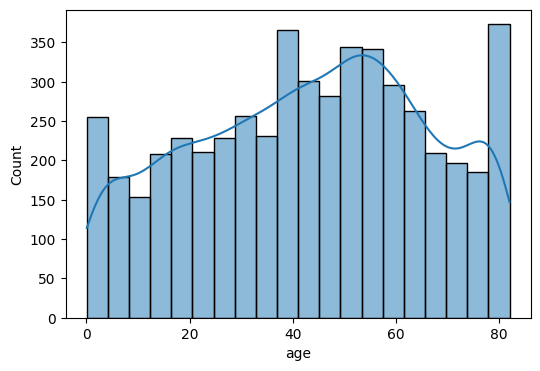

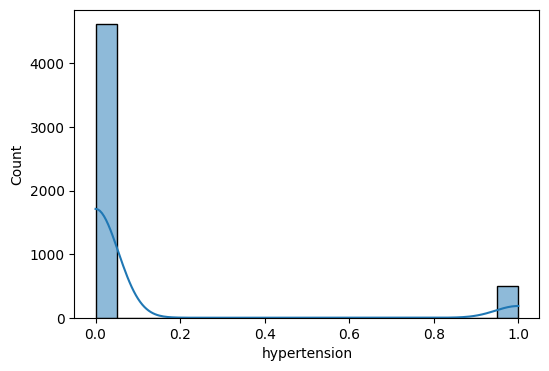

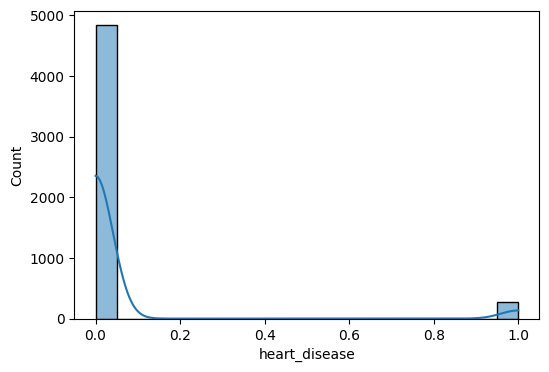

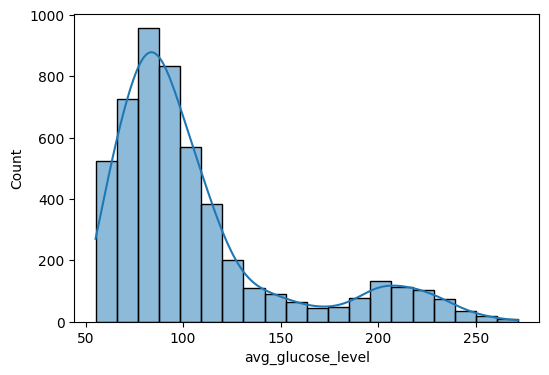

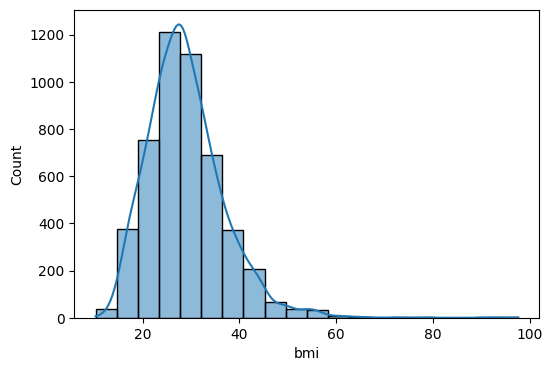

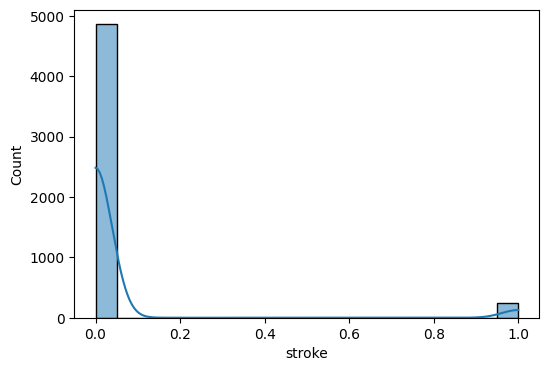

In [69]:
for col in num_cols:
    plt.figure(figsize=(6, 4))
    sns.histplot(df[col], kde=True, bins=20)

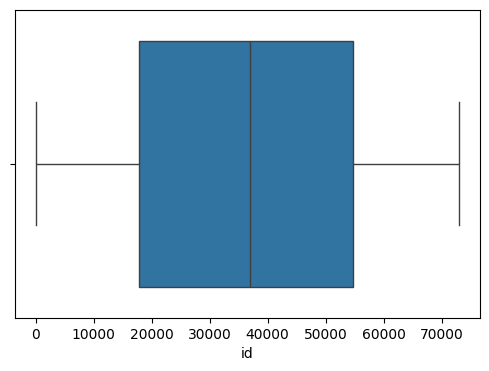

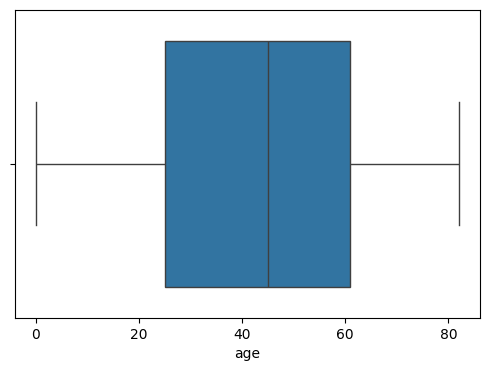

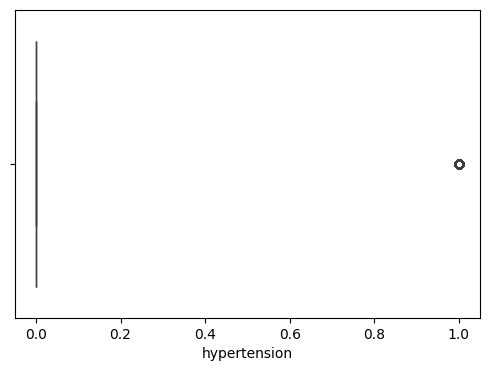

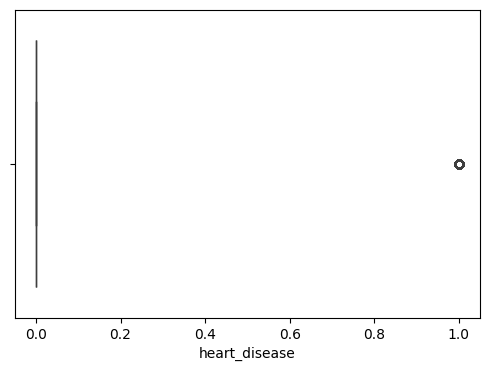

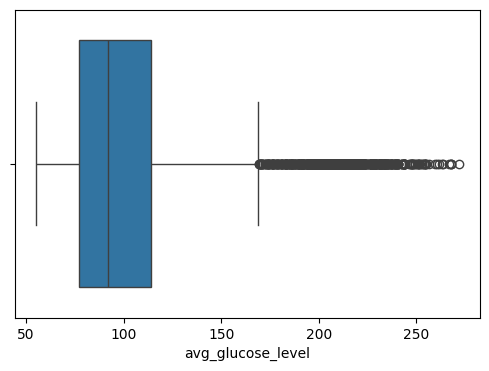

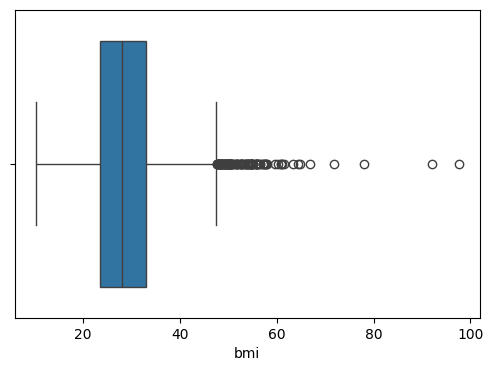

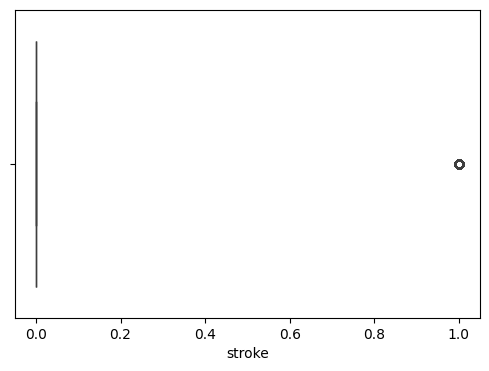

In [70]:
for col in num_cols:
    plt.figure(figsize=(6, 4))
    sns.boxplot(x=df[col])
    plt.show()

Correlation between numeric variables

<Axes: >

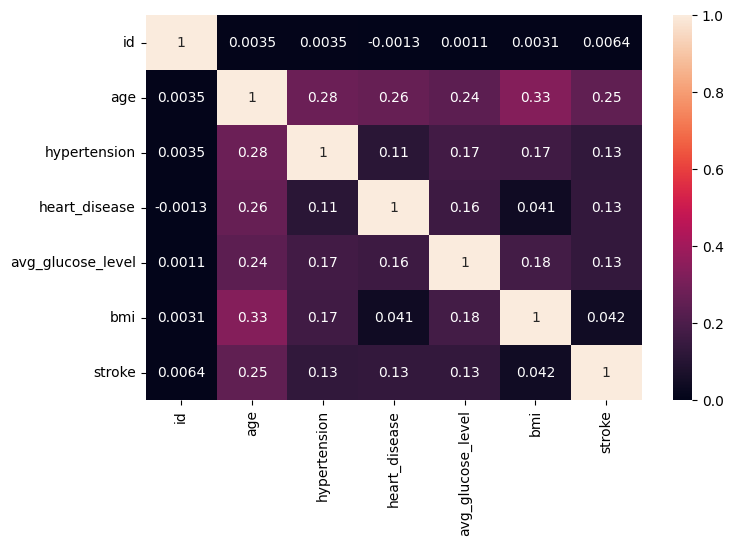

In [71]:
plt.figure(figsize=(8, 5))
sns.heatmap(df[num_cols].corr(), annot=True)

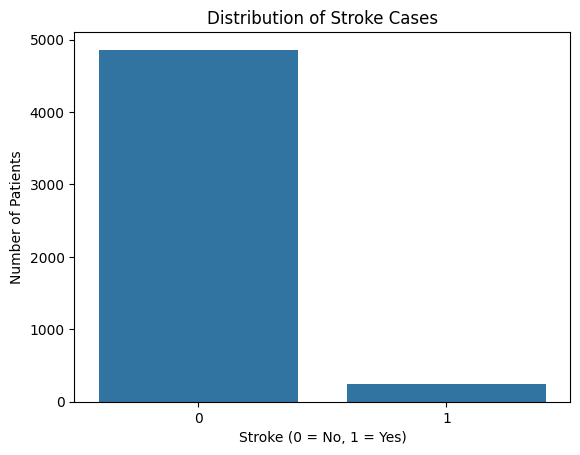

stroke
0    95.13
1     4.87
Name: proportion, dtype: float64

In [72]:

sns.countplot(data=df, x="stroke")
plt.title("Distribution of Stroke Cases")
plt.xlabel("Stroke (0 = No, 1 = Yes)")
plt.ylabel("Number of Patients")
plt.show()

(df["stroke"].value_counts(normalize=True) * 100).round(2)



#Data cleaning

'id' is not needed so remove it

In [73]:
df = df.drop(columns=["id"])


Now calculate the median of BMI and replace missing values with median, it is done so as replacing missing values with mean would affect the extreme values, also bmi contains lots of outliers so median is preferred

In [74]:
median = df["bmi"].median()

df["bmi"] = df["bmi"].fillna(median)

df["bmi"].isnull().sum()

df["bmi"].describe()

count    5110.000000
mean       28.862035
std         7.699562
min        10.300000
25%        23.800000
50%        28.100000
75%        32.800000
max        97.600000
Name: bmi, dtype: float64

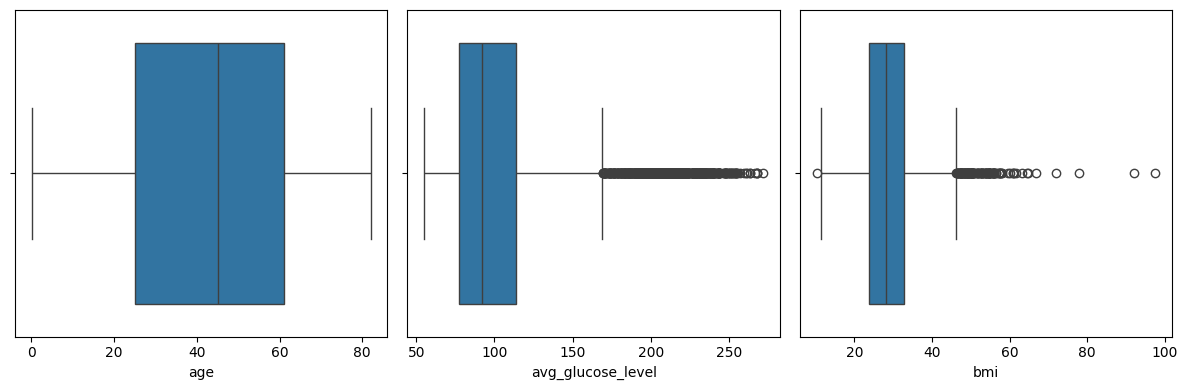

In [75]:
num_cols = [
    "age",
    "avg_glucose_level",
    "bmi"
]

plt.figure(figsize=(12, 4))

for i, col in enumerate(num_cols, 1):
    plt.subplot(1, 3, i)
    sns.boxplot(x=df[col])

plt.tight_layout()
plt.show()

Seperating numerical and categorical columns

In [76]:
categorical_cols = df.select_dtypes(include="object").columns.tolist()
num_cols = df.select_dtypes(include=np.number).columns.tolist()

print("Categorical columns:")
print(categorical_cols)

print("\nNumerical columns:")
print(num_cols)

Categorical columns:
['gender', 'ever_married', 'work_type', 'Residence_type', 'smoking_status']

Numerical columns:
['age', 'hypertension', 'heart_disease', 'avg_glucose_level', 'bmi', 'stroke']


In [77]:

correlation = df[num_cols].corr()

display(correlation["stroke"].sort_values(ascending=False))

stroke               1.000000
age                  0.245257
heart_disease        0.134914
avg_glucose_level    0.131945
hypertension         0.127904
bmi                  0.036110
Name: stroke, dtype: float64

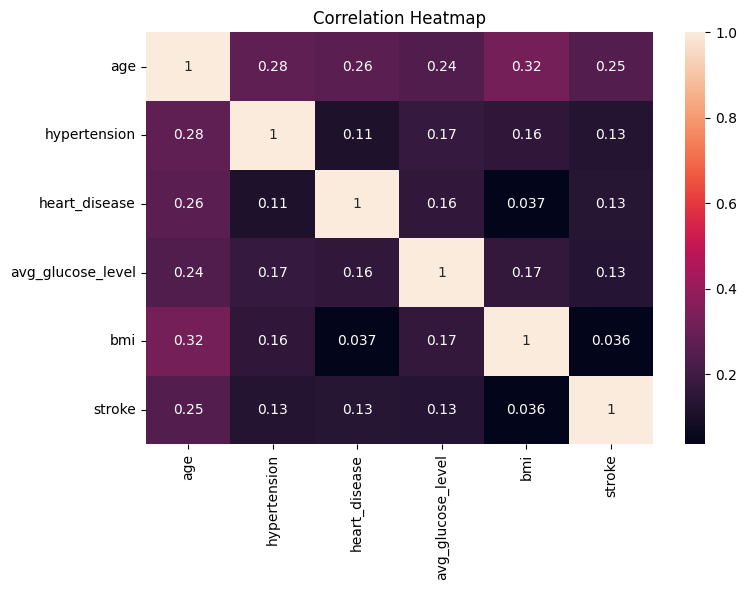

In [78]:
plt.figure(figsize=(8,6))

sns.heatmap(
    correlation,
    annot=True,
)

plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()

Encoding categorical features to numeric data

In [169]:

x = df.drop(columns=["stroke"])

x_enc = pd.get_dummies(
    x,
    columns=categorical_cols,
    drop_first=True,
    dtype=int
)

print("Original feature shape:", x.shape)
print("Encoded feature shape:", x_enc.shape)

display(x_enc.head())

Original feature shape: (5110, 10)
Encoded feature shape: (5110, 16)


,age,hypertension,heart_disease,avg_glucose_level,bmi,gender_Male,gender_Other,ever_married_Yes,work_type_Never_worked,work_type_Private,work_type_Self-employed,work_type_children,Residence_type_Urban,smoking_status_formerly smoked,smoking_status_never smoked,smoking_status_smokes
0,67.0,0,1,228.69,36.6,1,0,1,0,1,0,0,1,1,0,0
1,61.0,0,0,202.21,28.1,0,0,1,0,0,1,0,0,0,1,0
2,80.0,0,1,105.92,32.5,1,0,1,0,1,0,0,0,0,1,0
3,49.0,0,0,171.23,34.4,0,0,1,0,1,0,0,1,0,0,1
4,79.0,1,0,174.12,24.0,0,0,1,0,0,1,0,0,0,1,0


Checking missing and duplicate rows in encoded features

In [170]:
print("Missing values:", x_enc.isnull().sum().sum())
print("Duplicate rows:", x_enc.duplicated().sum())

Missing values: 0
Duplicate rows: 0


#Splitting dataset into training and testing 

In [171]:
# Input features and target variable
X = x_enc
y = df["stroke"]

print("Number of features:", X.shape[1])
print("Number of samples:", X.shape[0])
print("Target distribution:")
print(y.value_counts())

Number of features: 16
Number of samples: 5110
Target distribution:
stroke
0    4861
1     249
Name: count, dtype: int64


In [148]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts())

print("\nTesting target distribution:")
print(y_test.value_counts())

Training features: (4088, 16)
Testing features: (1022, 16)

Training target distribution:
stroke
0    3889
1     199
Name: count, dtype: int64

Testing target distribution:
stroke
0    972
1     50
Name: count, dtype: int64


Logistic Regression Model

In [172]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression(
    max_iter=1000,
    class_weight="balanced"
)

model.fit(X_train, y_train)

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,'balanced'
,random_state,None
,solver,'lbfgs'
,max_iter,1000
,multi_class,'deprecated'


In [173]:
y_pred = model.predict(X_test)

print(y_pred[:10])

[0 0 0 0 1 0 0 0 0 0]


In [174]:
from sklearn.metrics import accuracy_score
from sklearn.metrics import classification_report

accuracy = accuracy_score(y_test, y_pred)

print(f"Accuracy: {accuracy:.4f}\n")

print(classification_report(y_test, y_pred))

Accuracy: 0.7466

              precision    recall  f1-score   support

           0       0.99      0.74      0.85       972
           1       0.14      0.80      0.24        50

    accuracy                           0.75      1022
   macro avg       0.56      0.77      0.54      1022
weighted avg       0.94      0.75      0.82      1022



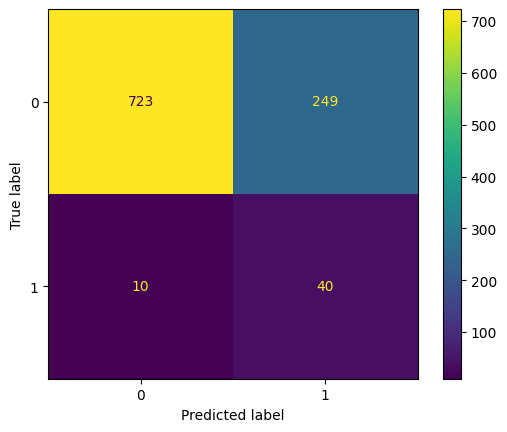

In [175]:
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(y_test,y_pred)
plt.show()

Random Forest Model

In [107]:
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(
    n_estimators=200,
    class_weight="balanced",
    random_state=42
)

rf_model.fit(X_train, y_train)

,n_estimators,200
,criterion,'gini'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [108]:
rf_pred = rf_model.predict(X_test)

print("Accuracy:", accuracy_score(y_test, rf_pred))

print("\nClassification Report:")
print(classification_report(y_test, rf_pred))

Accuracy: 0.9500978473581213

Classification Report:
              precision    recall  f1-score   support

           0       0.95      1.00      0.97       972
           1       0.00      0.00      0.00        50

    accuracy                           0.95      1022
   macro avg       0.48      0.50      0.49      1022
weighted avg       0.90      0.95      0.93      1022



Comparing two models

,Model,Accuracy,Precision,Recall,F1-score
0,Logistic Regression,0.7466,0.1384,0.8,0.236
1,Random Forest,0.9501,0.0000,0.0,0.000


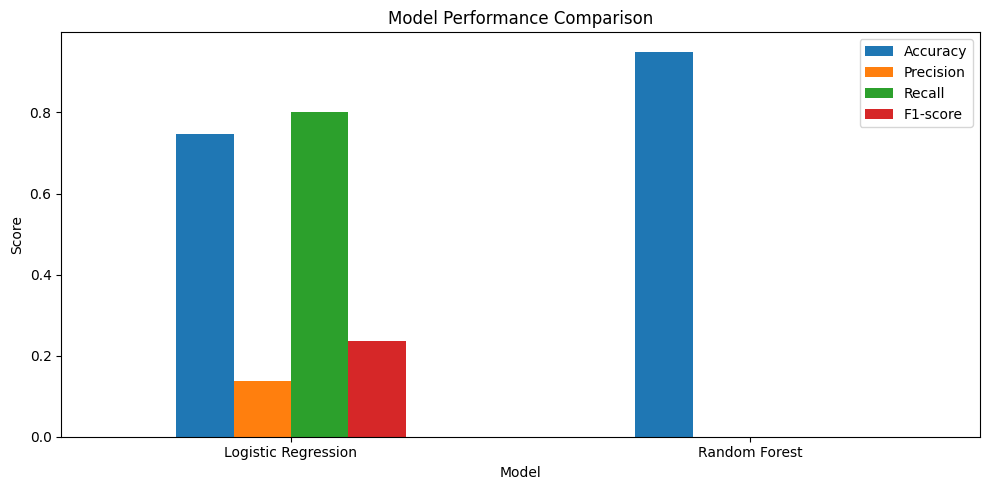

In [131]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

results = pd.DataFrame({
    "Model": ["Logistic Regression", "Random Forest"],
    "Accuracy": [
        accuracy_score(y_test, y_pred),
        accuracy_score(y_test, rf_pred)
    ],
    "Precision": [
        precision_score(y_test, y_pred, zero_division=0),
        precision_score(y_test, rf_pred, zero_division=0)
    ],
    "Recall": [
        recall_score(y_test, y_pred, zero_division=0),
        recall_score(y_test, rf_pred, zero_division=0)
    ],
    "F1-score": [
        f1_score(y_test, y_pred, zero_division=0),
        f1_score(y_test, rf_pred, zero_division=0)
    ]
})

display(results.round(4))

results.set_index("Model").plot(
    kind="bar",
    figsize=(10, 5)
)

plt.title("Model Performance Comparison")
plt.ylabel("Score")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [180]:
# Create a sample using an existing test row
sample = X_test.iloc[[10]]

# Predict the result
prediction = model.predict(sample)

print("Prediction:", prediction[0])

if prediction[0] == 1:
    print("The model predicts the stroke class.")
else:
    print("The model predicts the non-stroke class.")

Prediction: 1
The model predicts the stroke class.
